# Antimalarial activity prediction: full pipeline
The code lives in the `.py` files in this folder (`config`, `graphs`, `splits`, `data_prep`, `eda`, `descriptors`, `models`, `train`, `tune`, `train_final`, `evaluate`, `curves`, `explain`, `plots`). This notebook only imports them and runs the stages, top to bottom.

* Tuning is **resumable**: if the session stops, run the *tune* cell again.
* `QUICK = False` is the real run. `QUICK = True` is a few-minute smoke test whose results go into a separate `quick_test/` folder, so they can never be mistaken for real ones.
* A GPU makes this several times faster.

In [ ]:
!pip install -q shap captum

## 1. Settings

In [2]:
import os, time
import pandas as pd, torch

import config, data_prep, eda, tune, train_final, evaluate, curves, explain, plots

# ---- your three input files go in the main_data_2 folder, next to this notebook and the .py files ----
DATA        = "main_data_2/Drug_activity.csv"                         # SMILES + label columns
GRAPHS      = "main_data_2/molecule_graphs.pt"                        # your graphs (dict SMILES -> Data, or list of Data with .smiles)
DESCRIPTORS = "main_data_2/enhanced_drug_data_with_descriptors.csv"   # your descriptors (SMILES + numeric columns); None = compute with RDKit
OUT         = "."                                         # results are written here
SMILES_COL, LABEL_COL = "Smiles", "Labels"

# ---- run options ------------------------------------------------------------
QUICK = False           # False = the real run (up to 200 epochs, early stopping). True = tiny smoke test, saved in quick_test/
SEEDS = [42, 43, 44]    # final-training repeats (reviewers asked for repeated evaluation)
AMP   = False           # mixed precision on a GPU: faster, try True once the run works
EXPLAIN_MODEL = "gat_transformer"   # gcn | gat | gcn_transformer | gat_transformer
EXPLAIN_N = 50                      # compounds explained (random, class-balanced sample of the test set)

config.CFG.update(data_path=DATA, graph_path=GRAPHS, desc_path=DESCRIPTORS, build_missing=False, out_dir=OUT,
                  smiles_col=SMILES_COL, label_col=LABEL_COL, amp=AMP, limit=None)
config.CFG["explain_n"] = EXPLAIN_N
# ---- accuracy levers (all on by default; see README). Switch off one at a time to test their effect on the validation folds ----
# config.CFG.update(resample_each_epoch=True, embed_categorical=True, ensemble=True)
if QUICK:
    config.apply_quick(); SEEDS = SEEDS[:2]
OUT = config.CFG["out_dir"]   # quick runs write to <OUT>/quick_test, real runs to <OUT>
torch.set_num_threads(os.cpu_count() or 1)
print("device:", config.DEVICE, "| quick:", QUICK, "| seeds:", SEEDS)

device: cpu | quick: False | seeds: [42, 43, 44]


## 2. Prepare: clean data, load graphs and descriptors, scaffold splits

In [3]:
t0 = time.time()
data_prep.prepare()
print(f'done in {(time.time() - t0) / 60:.1f} min')


===== prepare started 2026-11-13 07:46:27 =====
126819 labelled rows, 123755 after removing exact duplicate rows
using your descriptor file: 208 numeric columns
10 molecules have no graph in your file and are dropped
10 molecules have no row in your descriptor file and are dropped
123745 valid molecules (12685 active, 111060 inactive, 10.3% active)
SMILES with conflicting labels: 264
         subset  compounds  active  inactive  active_pct
   Full dataset     123745   12685    111060       10.25
Development set      98995    9962     89033       10.06
       Test set      24750    2723     22027       11.00
208 descriptors; prepare took 25s
===== prepare finished in 0.4 min =====
done in 0.4 min


## 3. Look at the data (before any training)
Each cell writes into `eda/`. The split figure is drawn from the splits the pipeline actually uses (Bemis-Murcko scaffold split).

In [4]:
data, df, descriptor_cols = eda.load_eda_data()


===== class_balance started 2026-11-13 07:47:50 =====


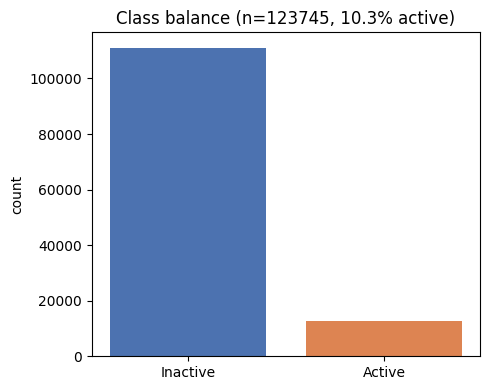

===== class_balance finished in 0.0 min =====


In [5]:
eda.class_balance(df)


===== descriptor_distributions started 2026-11-13 07:48:01 =====


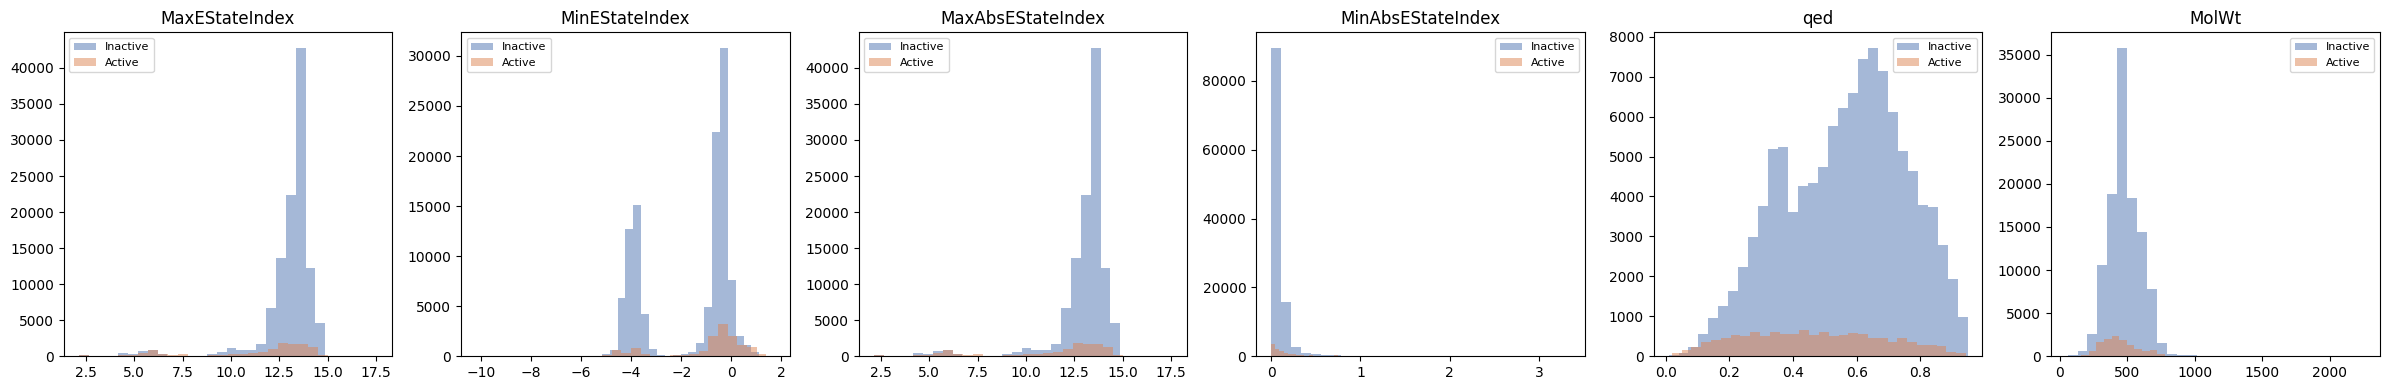

===== descriptor_distributions finished in 0.0 min =====


In [6]:
eda.descriptor_distributions(df, descriptor_cols)


===== correlation_heatmap started 2026-11-13 07:48:06 =====


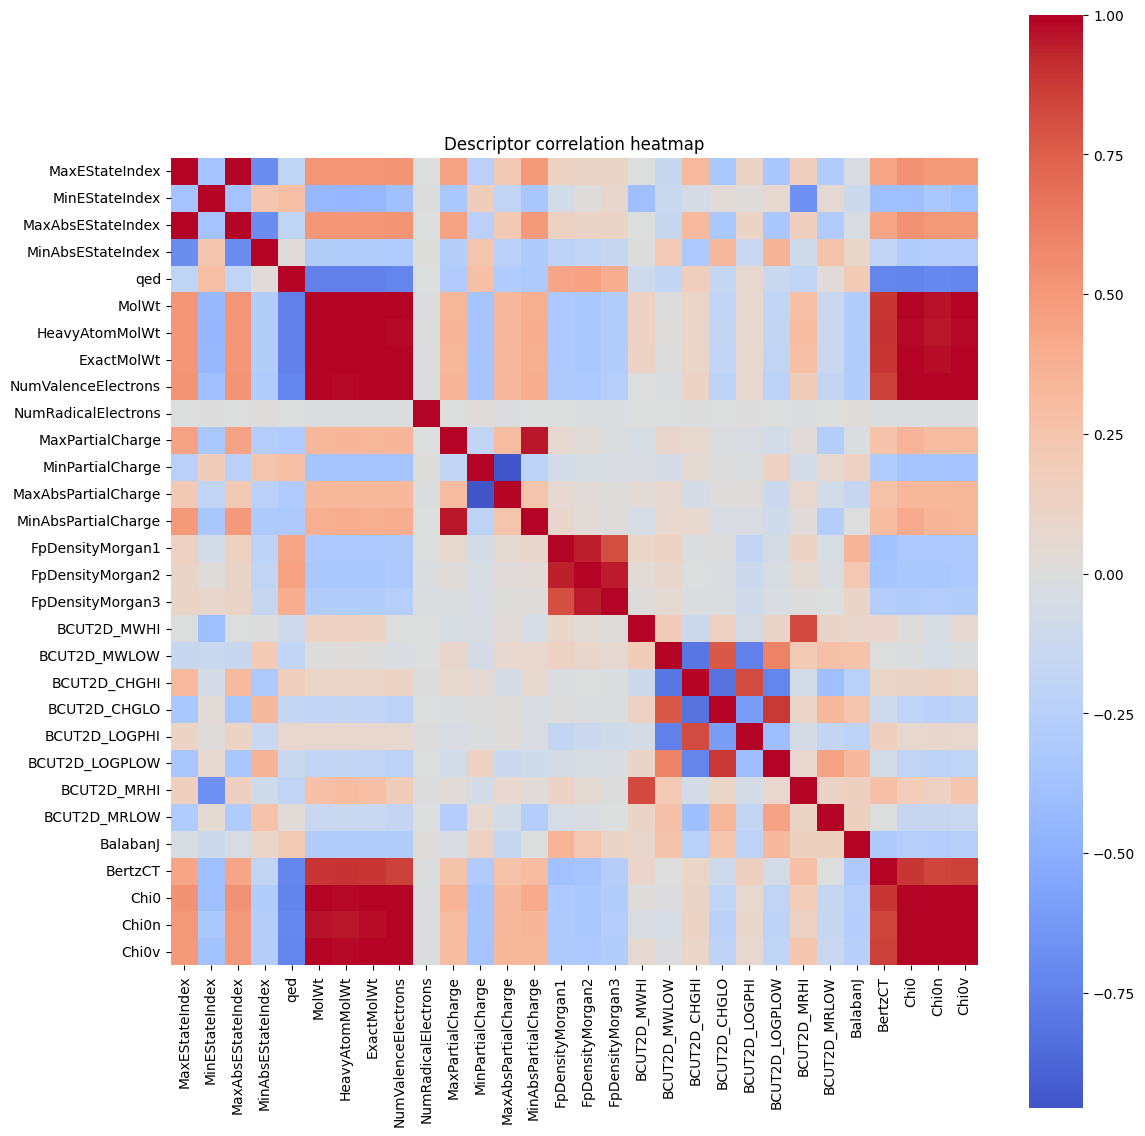

===== correlation_heatmap finished in 0.0 min =====


In [7]:
eda.correlation_heatmap(df, descriptor_cols)


===== sample_molecules started 2026-11-13 07:48:09 =====


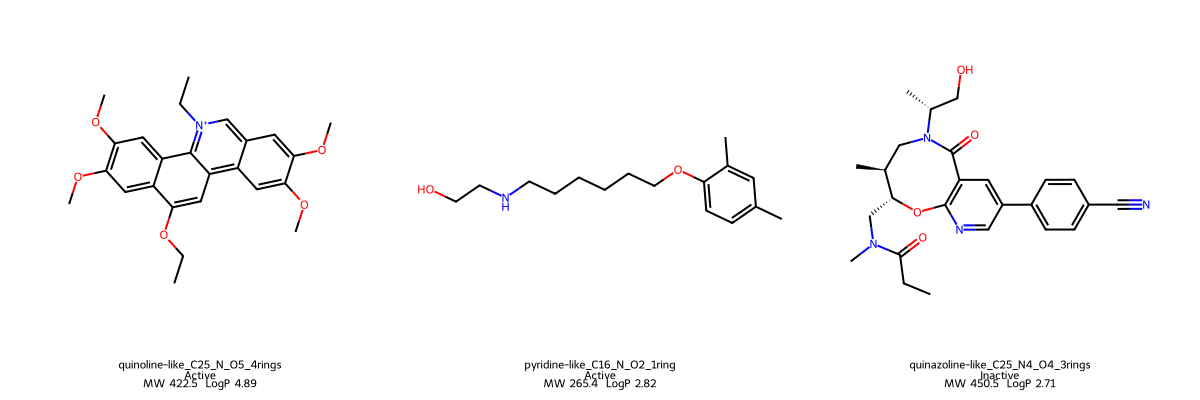

saved ./eda/sample_molecules.png
===== sample_molecules finished in 0.0 min =====


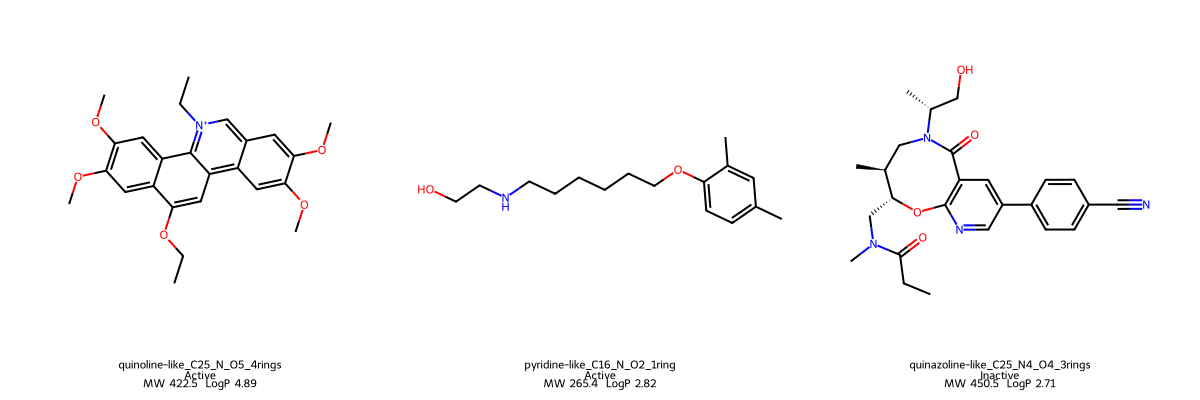

In [8]:
eda.sample_molecules(df)


===== extreme_molecules started 2026-11-13 07:48:13 =====


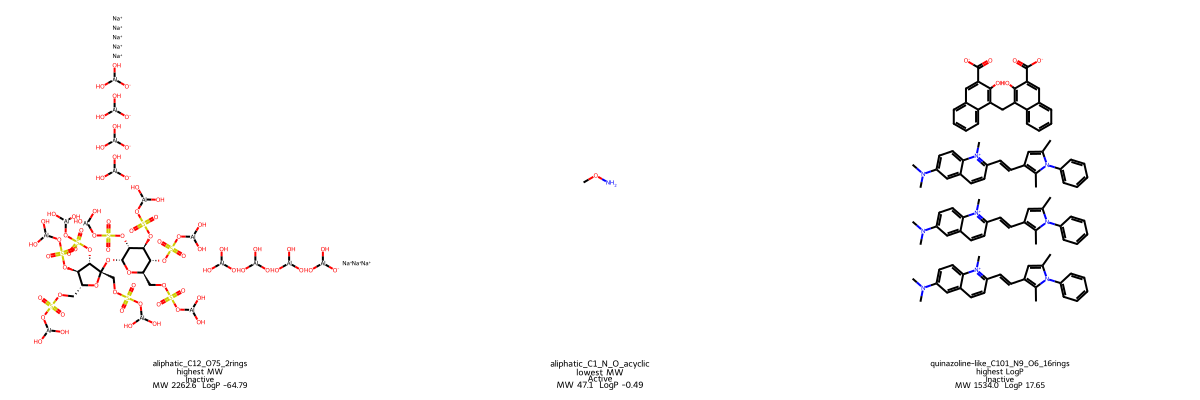

saved ./eda/extreme_molecules.png
===== extreme_molecules finished in 0.0 min =====


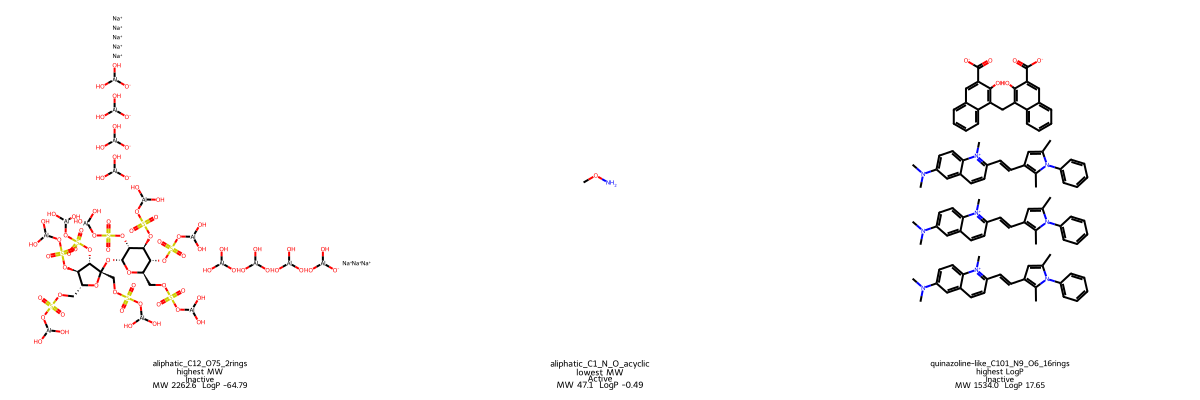

In [9]:
eda.extreme_molecules(df)

In [10]:
eda.descriptor_statistics(df, descriptor_cols)


===== descriptor_statistics started 2026-11-13 07:48:19 =====
196 of 208 descriptors differ between actives and inactives (FDR < 0.05)
===== descriptor_statistics finished in 0.0 min =====


,descriptor,active_mean,active_std,inactive_mean,inactive_std,p_value,p_value_fdr,significant
0,MaxEStateIndex,11.125398,3.249549,13.007597,1.570376,0.0,0.0,True
206,fr_unbrch_alkane,0.698699,2.167287,0.055114,0.468914,0.0,0.0,True
97,VSA_EState4,3.448140,3.444540,2.005100,1.841682,0.0,0.0,True
96,VSA_EState3,10.459859,10.197226,12.438390,6.812438,0.0,0.0,True
95,VSA_EState2,19.229148,15.443986,24.618314,12.368573,0.0,0.0,True
94,VSA_EState10,1.937943,3.727833,0.765573,2.363583,0.0,0.0,True
93,VSA_EState1,15.031402,17.522811,23.290767,19.739710,0.0,0.0,True
92,EState_VSA9,11.630827,9.950464,8.309854,6.793639,0.0,0.0,True
89,EState_VSA6,18.053299,18.182816,27.285842,18.858719,0.0,0.0,True
87,EState_VSA4,30.367005,21.346139,20.815219,15.525399,0.0,0.0,True



===== split_overview started 2026-11-13 07:48:24 =====


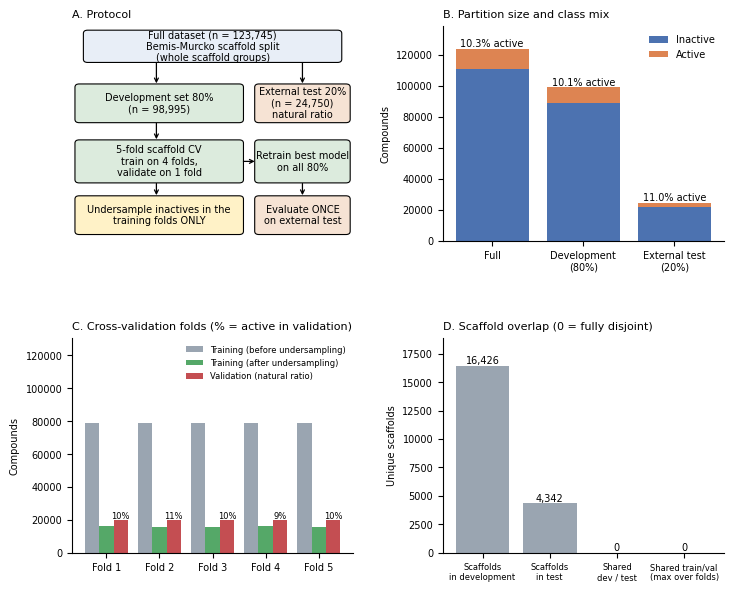

saved ./eda/data_split_overview.pdf
===== split_overview finished in 0.0 min =====


{'n_dev': 98995, 'n_test': 24750, 'shared_scaffolds_dev_test': 0}

In [11]:
eda.split_overview(data)

## 4. Tune: random search with 5-fold scaffold cross-validation (development set only)

In [12]:
t0 = time.time()
tune.tune()
print(f'done in {(time.time() - t0) / 60:.1f} min')


===== tune started 2026-11-13 07:48:40 =====
tuning gcn
  gcn cfg 0 fold 0: AUROC 0.9379 (17 epochs, 169.9s)
  gcn cfg 1 fold 0: AUROC 0.9389 (16 epochs, 58.1s)
  gcn cfg 2 fold 0: AUROC 0.9359 (20 epochs, 68.3s)
  gcn cfg 3 fold 0: AUROC 0.9385 (20 epochs, 197.2s)
  gcn cfg 4 fold 0: AUROC 0.9348 (20 epochs, 90.7s)
  gcn cfg 5 fold 0: AUROC 0.9347 (20 epochs, 75.3s)
  gcn cfg 6 fold 0: AUROC 0.9390 (20 epochs, 67.1s)
  gcn cfg 7 fold 0: AUROC 0.9363 (20 epochs, 73.3s)
  gcn cfg 8 fold 0: AUROC 0.9396 (20 epochs, 338.3s)
  gcn cfg 9 fold 0: AUROC 0.9375 (20 epochs, 113.5s)
  gcn cfg 10 fold 0: AUROC 0.9386 (14 epochs, 172.8s)
  gcn cfg 11 fold 0: AUROC 0.9401 (20 epochs, 240.3s)
  gcn cfg 12 fold 0: AUROC 0.9389 (20 epochs, 127.5s)
  gcn cfg 13 fold 0: AUROC 0.9378 (17 epochs, 95.1s)
  gcn cfg 14 fold 0: AUROC 0.9389 (20 epochs, 157.2s)
  gcn cfg 15 fold 0: AUROC 0.9377 (15 epochs, 85.4s)
  gcn cfg 16 fold 0: AUROC 0.9358 (20 epochs, 68.2s)
  gcn cfg 17 fold 0: AUROC 0.9378 (20 epochs

## 5. Final training and test predictions

In [13]:
t0 = time.time()
train_final.final(SEEDS)
print(f'done in {(time.time() - t0) / 60:.1f} min')


===== final started 2026-11-13 22:59:30 =====
final fit: 16604 training (undersampled), 14892 validation, 24750 test compounds, 159 descriptors kept
  gcn seed 42: val AUROC 0.9359, test AUROC 0.9403, AP 0.6909 (64 epochs, 1065s)
  gcn seed 43: val AUROC 0.9350, test AUROC 0.9389, AP 0.6893 (50 epochs, 792s)
  gcn seed 44: val AUROC 0.9368, test AUROC 0.9400, AP 0.6961 (61 epochs, 948s)
  gcn: reported result (mean of 3 seed(s)): test AUROC 0.9414, AP 0.6989
  gat seed 42: val AUROC 0.9372, test AUROC 0.9407, AP 0.6939 (52 epochs, 829s)
  gat seed 43: val AUROC 0.9380, test AUROC 0.9388, AP 0.6883 (54 epochs, 842s)
  gat seed 44: val AUROC 0.9362, test AUROC 0.9410, AP 0.7005 (59 epochs, 927s)
  gat: reported result (mean of 3 seed(s)): test AUROC 0.9426, AP 0.7036
  gcn_transformer seed 42: val AUROC 0.9364, test AUROC 0.9400, AP 0.6921 (54 epochs, 1240s)
  gcn_transformer seed 43: val AUROC 0.9376, test AUROC 0.9400, AP 0.6892 (50 epochs, 1214s)
  gcn_transformer seed 44: val AUROC 

## 6. Report: metrics, bootstrap CIs, DeLong tests

In [14]:
t0 = time.time()
evaluate.report()
print(f'done in {(time.time() - t0) / 60:.1f} min')


===== report started 2026-11-14 02:36:01 =====
              Model      AUC     AUC 95% CI   PR-AUC  PR-AUC 95% CI
                GCN 0.941353 (0.937, 0.945) 0.698865 (0.683, 0.716)
                GAT 0.942582 (0.939, 0.946) 0.703609 (0.686, 0.720)
    GCN-Transformer 0.941356 (0.937, 0.945) 0.696617 (0.679, 0.713)
    GAT-Transformer 0.943276 (0.939, 0.947) 0.703706 (0.686, 0.721)
  Gradient Boosting 0.934218 (0.930, 0.938) 0.640859 (0.623, 0.660)
      Random Forest 0.931710 (0.927, 0.936) 0.641851 (0.622, 0.660)
Logistic Regression 0.917954 (0.913, 0.923) 0.580536 (0.560, 0.601)
         Linear SVM 0.917803 (0.913, 0.923) 0.577903 (0.557, 0.599)
               k-NN 0.911708 (0.906, 0.917) 0.571012 (0.552, 0.590)
tables written to .
===== report finished in 1.7 min =====
done in 1.7 min


## 7. Learning curves (5-fold scaffold CV, all nine models)

In [15]:
t0 = time.time()
curves.curves()
print(f'done in {(time.time() - t0) / 60:.1f} min')


===== curves started 2026-11-14 02:37:44 =====
  fold 1 fraction 0.1: gcn n=1612 AUROC 0.920
  fold 1 fraction 0.1: gat n=1612 AUROC 0.918
  fold 1 fraction 0.1: gcn_transformer n=1612 AUROC 0.920
  fold 1 fraction 0.1: gat_transformer n=1612 AUROC 0.918
  fold 1 fraction 0.1: gradient_boosting n=1612 AUROC 0.910
  fold 1 fraction 0.1: random_forest n=1612 AUROC 0.909
  fold 1 fraction 0.1: logistic_regression n=1612 AUROC 0.893
  fold 1 fraction 0.1: linear_svm n=1612 AUROC 0.897
  fold 1 fraction 0.1: knn n=1612 AUROC 0.881
  fold 1 fraction 0.2: gcn n=3224 AUROC 0.926
  fold 1 fraction 0.2: gat n=3224 AUROC 0.921
  fold 1 fraction 0.2: gcn_transformer n=3224 AUROC 0.926
  fold 1 fraction 0.2: gat_transformer n=3224 AUROC 0.924
  fold 1 fraction 0.2: gradient_boosting n=3224 AUROC 0.919
  fold 1 fraction 0.2: random_forest n=3224 AUROC 0.917
  fold 1 fraction 0.2: logistic_regression n=3224 AUROC 0.906
  fold 1 fraction 0.2: linear_svm n=3224 AUROC 0.908
  fold 1 fraction 0.2: knn n

## 8. Figures


===== plots started 2026-11-14 18:25:50 =====


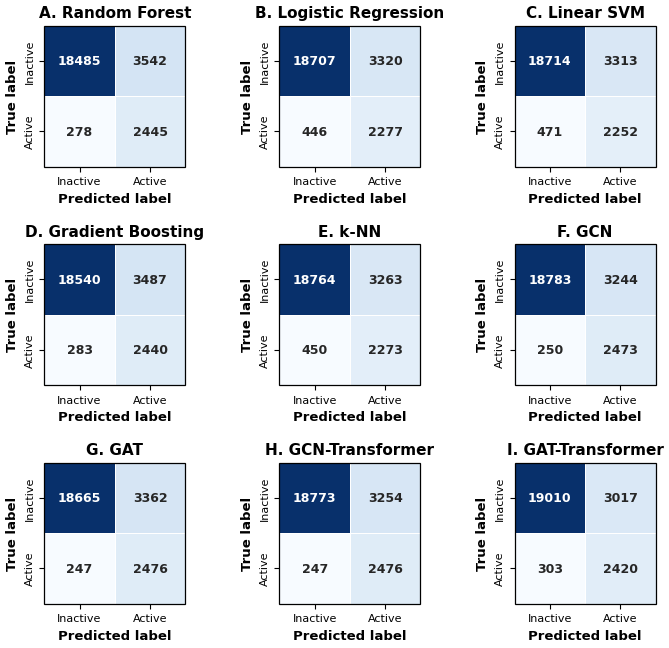

  saved figures/confusion_matrices.pdf


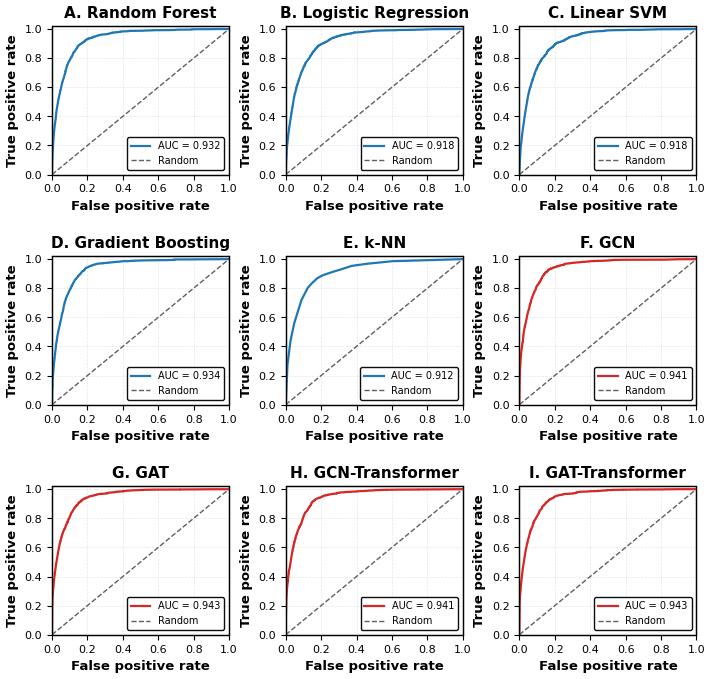

  saved figures/roc_curves.pdf


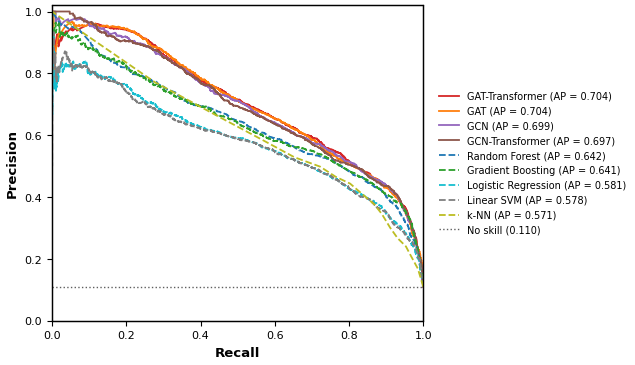

  saved figures/pr_curves.pdf


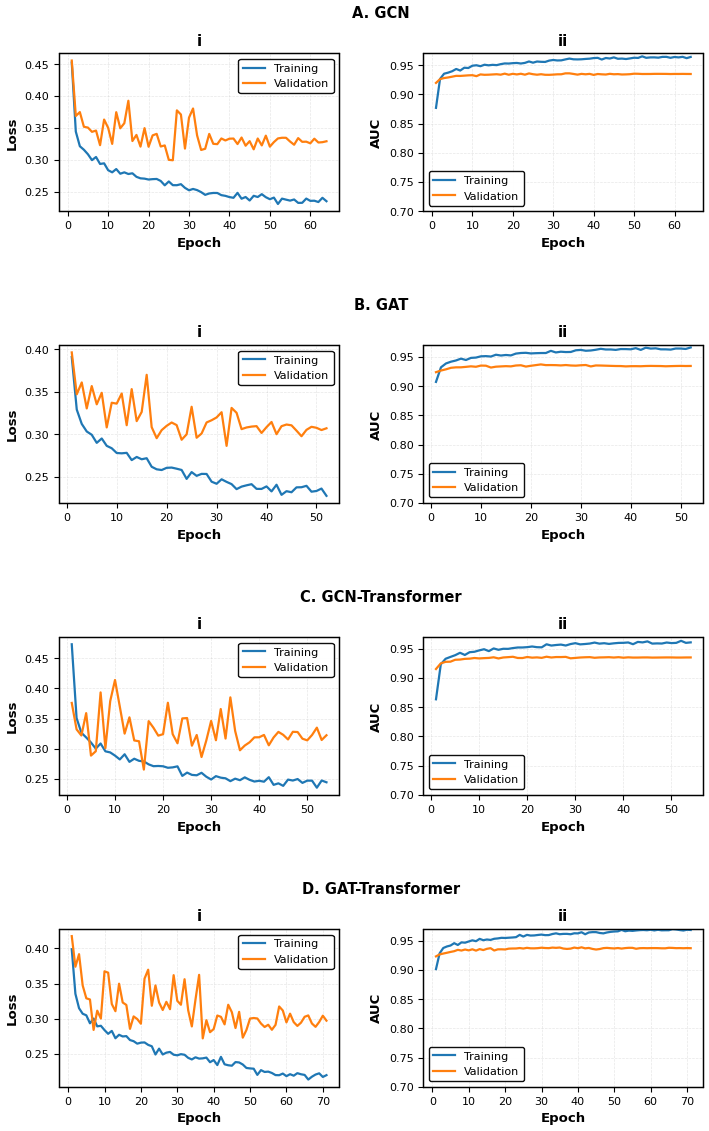

  saved figures/training_curves.pdf


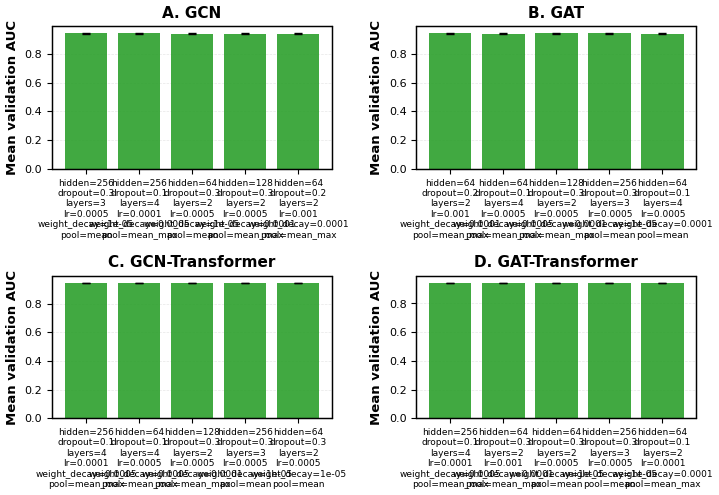

  saved figures/tuning_results.pdf


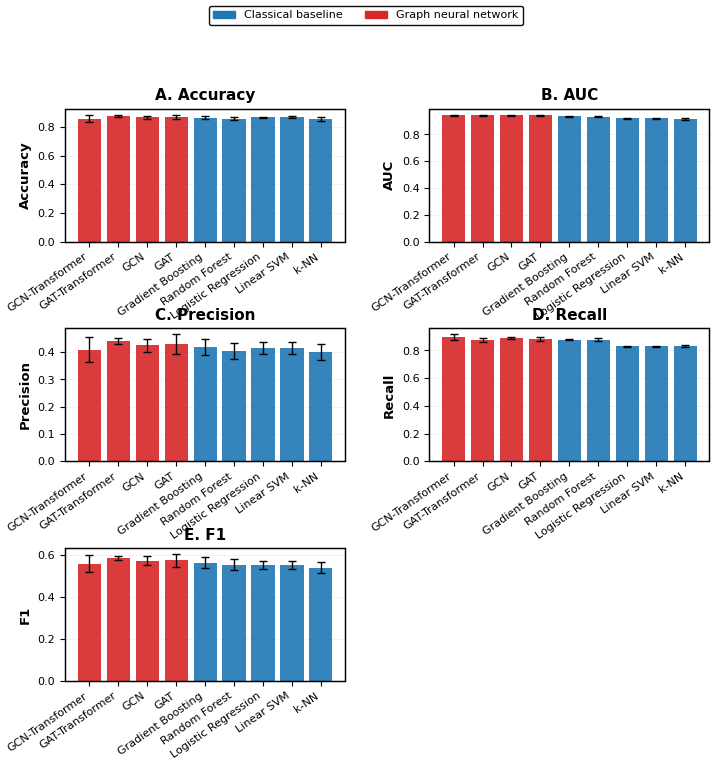

  saved figures/metrics_comparison.pdf


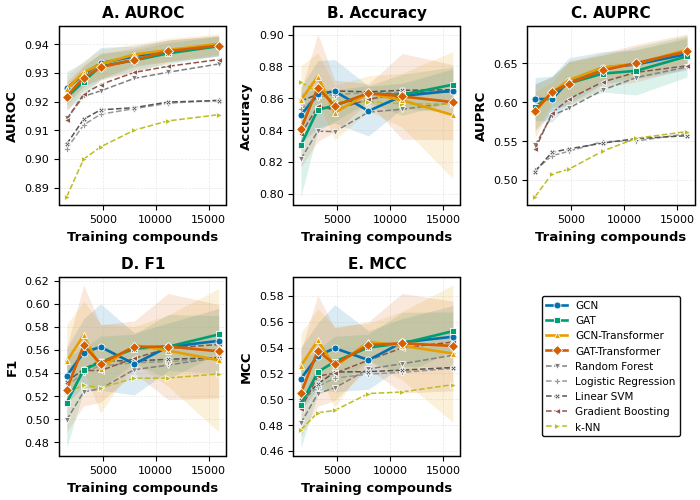

  saved figures/learning_curves.pdf


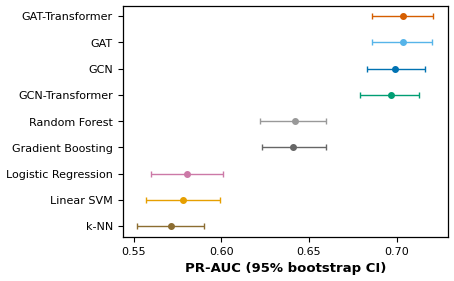

  saved figures/prauc_ci.pdf (+ .png)


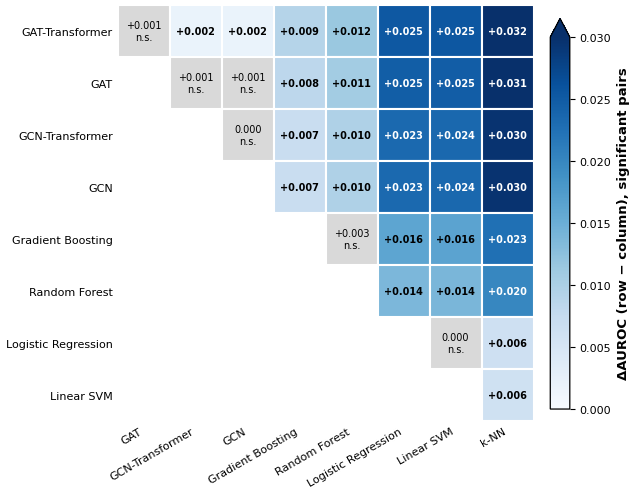

  saved figures/delong_heatmap.pdf (+ .png)
===== plots finished in 0.1 min =====
done in 0.1 min


In [29]:
t0 = time.time()
plots.plots()
print(f'done in {(time.time() - t0) / 60:.1f} min')

## 9. Explainability (post-hoc, feature level)
Five methods, each applied to both branches (atomic graph features and molecular descriptors) of the chosen model. First the **saved models are loaded** (no retraining), then each method runs in its own cell. Results are written to `explainability/` (CSV) and `figures/` (PDF). These explanations are hypotheses about what the model uses; they are not validated experimentally.

In [17]:
models, ctx, fd = explain.load_trained_models()   # loads the saved weights from trained_models/

loaded gnn_model (seed 42)
loaded gat_model (seed 42)
loaded gcn_transformer_model (seed 42)
loaded gat_transformer_model (seed 42)


In [18]:
setup = explain.make_setup(models[EXPLAIN_MODEL], ctx, fd, n=config.CFG['explain_n'])

explaining 50 random test compounds (25 active), 159 descriptors



===== run_gnnexplainer started 2026-11-14 18:44:59 =====


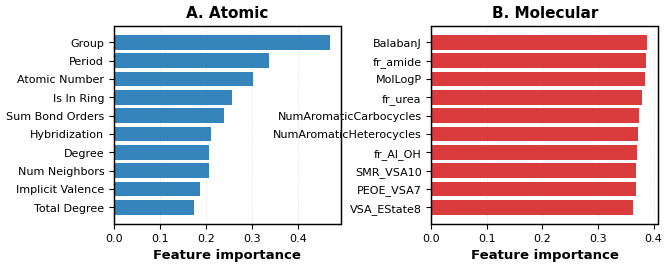

Saved feature-importance figure to ./figures/gnnexplainer_atomic_vs_molecular.pdf
===== run_gnnexplainer finished in 1.2 min =====


(                  feature  importance
 0                   Group    0.469508
 1                  Period    0.336683
 2           Atomic Number    0.301335
 3              Is In Ring    0.255912
 4         Sum Bond Orders    0.239806
 5           Hybridization    0.210551
 6                  Degree    0.206539
 7           Num Neighbors    0.205781
 8        Implicit Valence    0.186423
 9            Total Degree    0.174694
 10        Num Implicit Hs    0.173236
 11            Is Aromatic    0.148419
 12              Num Rings    0.132798
 13          Total H Count    0.128781
 14       In 6-member Ring    0.111039
 15          Is Heteroatom    0.085006
 16       In 8-member Ring    0.044107
 17              Is Chiral    0.033691
 18        Num Explicit Hs    0.028765
 19       In 5-member Ring    0.025324
 20       In 4-member Ring    0.009201
 21             Is Halogen    0.005097
 22       In 3-member Ring    0.004490
 23       In 7-member Ring    0.003598
 24          Formal Charg

In [31]:
explain.run_gnnexplainer(setup)          # GNNExplainer (atomic + molecular)


===== run_integrated_gradients started 2026-11-14 11:37:24 =====


/opt/miniconda3/envs/DA/lib/python3.10/site-packages/captum/attr/_utils/batching.py:51: UserWarning: Internal batch size cannot be less than the number of input examples. Defaulting to internal batch size of 1700 equal to the number of examples.
  warnings.warn(
/opt/miniconda3/envs/DA/lib/python3.10/site-packages/captum/attr/_utils/batching.py:51: UserWarning: Internal batch size cannot be less than the number of input examples. Defaulting to internal batch size of 50 equal to the number of examples.
  warnings.warn(


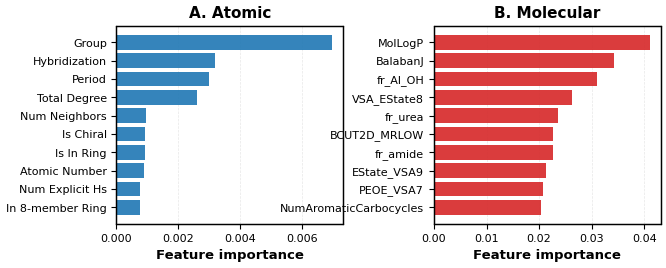

Saved feature-importance figure to ./figures/integrated_gradients_atomic_vs_molecular.pdf
===== run_integrated_gradients finished in 0.1 min =====


(                  feature  importance
 0                   Group    0.006986
 1           Hybridization    0.003175
 2                  Period    0.002984
 3            Total Degree    0.002608
 4           Num Neighbors    0.000940
 5               Is Chiral    0.000913
 6              Is In Ring    0.000908
 7           Atomic Number    0.000898
 8         Num Explicit Hs    0.000776
 9        In 8-member Ring    0.000771
 10                 Degree    0.000755
 11       Implicit Valence    0.000740
 12        Sum Bond Orders    0.000668
 13        Num Implicit Hs    0.000615
 14            Is Aromatic    0.000487
 15              Num Rings    0.000486
 16          Total H Count    0.000309
 17          Is Heteroatom    0.000249
 18       In 6-member Ring    0.000221
 19       In 5-member Ring    0.000163
 20       In 4-member Ring    0.000127
 21       In 3-member Ring    0.000095
 22       In 7-member Ring    0.000039
 23          Formal Charge    0.000022
 24             Is Haloge

In [20]:
explain.run_integrated_gradients(setup)  # Integrated Gradients (atomic + molecular)


===== run_feature_ablation started 2026-11-14 11:37:29 =====


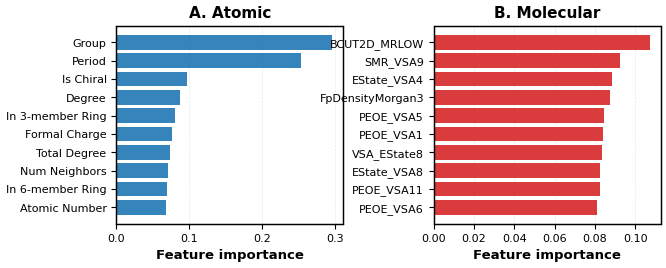

Saved feature-importance figure to ./figures/feature_ablation_atomic_vs_molecular.pdf
===== run_feature_ablation finished in 0.1 min =====


(                  feature  importance
 0                   Group    0.296463
 1                  Period    0.254154
 2               Is Chiral    0.096521
 3                  Degree    0.087908
 4        In 3-member Ring    0.080086
 5           Formal Charge    0.076103
 6            Total Degree    0.073617
 7           Num Neighbors    0.070863
 8        In 6-member Ring    0.069466
 9           Atomic Number    0.068089
 10       In 5-member Ring    0.065063
 11  Num Radical Electrons    0.063387
 12          Hybridization    0.062572
 13        Num Explicit Hs    0.062529
 14               Is Metal    0.059702
 15       Implicit Valence    0.058692
 16             Is In Ring    0.056701
 17       In 4-member Ring    0.056438
 18       In 7-member Ring    0.056076
 19       In 8-member Ring    0.055942
 20        Sum Bond Orders    0.055895
 21          Is Heteroatom    0.055152
 22              Num Rings    0.055147
 23          Total H Count    0.054437
 24            Is Aromati

In [21]:
explain.run_feature_ablation(setup)      # Feature Ablation (atomic + molecular)


===== run_saliency started 2026-11-14 11:37:36 =====


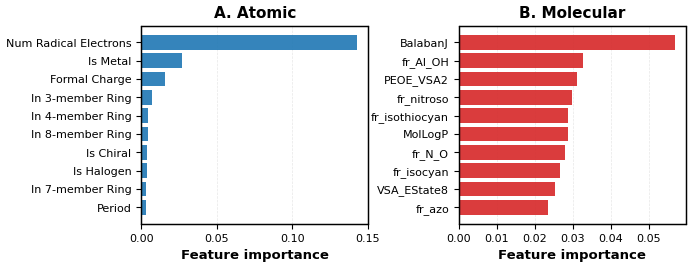

Saved feature-importance figure to ./figures/saliency_atomic_vs_molecular.pdf
===== run_saliency finished in 0.0 min =====


(                  feature  importance
 0   Num Radical Electrons    0.142922
 1                Is Metal    0.026746
 2           Formal Charge    0.015382
 3        In 3-member Ring    0.007157
 4        In 4-member Ring    0.004648
 5        In 8-member Ring    0.004404
 6               Is Chiral    0.004028
 7              Is Halogen    0.003513
 8        In 7-member Ring    0.003339
 9                  Period    0.002968
 10       In 5-member Ring    0.002270
 11        Num Explicit Hs    0.002238
 12            Is Aromatic    0.001048
 13              Num Rings    0.001002
 14             Is In Ring    0.000967
 15       In 6-member Ring    0.000888
 16          Is Heteroatom    0.000698
 17          Num Neighbors    0.000604
 18          Hybridization    0.000574
 19           Total Degree    0.000544
 20       Implicit Valence    0.000467
 21                  Group    0.000443
 22          Total H Count    0.000434
 23                 Degree    0.000422
 24        Num Implicit H

In [22]:
explain.run_saliency(setup)              # Saliency (atomic + molecular)


===== run_shap started 2026-11-14 11:37:37 =====


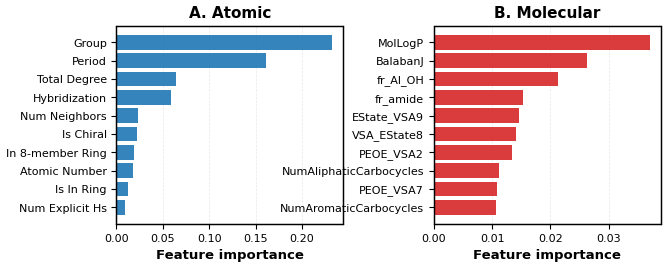

Saved feature-importance figure to ./figures/shap_atomic_vs_molecular.pdf
===== run_shap finished in 4.2 min =====


(                  feature  importance
 0                   Group    0.232954
 1                  Period    0.161000
 2            Total Degree    0.063780
 3           Hybridization    0.058581
 4           Num Neighbors    0.022884
 5               Is Chiral    0.022346
 6        In 8-member Ring    0.018590
 7           Atomic Number    0.017889
 8              Is In Ring    0.012224
 9         Num Explicit Hs    0.008958
 10              Num Rings    0.006363
 11       Implicit Valence    0.006109
 12            Is Aromatic    0.005337
 13                 Degree    0.004270
 14       In 4-member Ring    0.004192
 15       In 5-member Ring    0.003783
 16       In 3-member Ring    0.003686
 17          Is Heteroatom    0.002976
 18        Num Implicit Hs    0.002200
 19        Sum Bond Orders    0.001964
 20          Formal Charge    0.001940
 21       In 6-member Ring    0.001715
 22             Is Halogen    0.001354
 23          Total H Count    0.001320
 24       In 7-member Rin

In [23]:
explain.run_shap(setup)                  # SHAP (atomic + molecular): the slowest of the five

### How far do the five methods agree? (reviewer request: report partial agreement, not just the top features)


===== run_agreement started 2026-11-14 11:41:47 =====
          spearman               top_k_overlap          
              mean    min    max          mean  min  max
branch                                                  
Atomic       0.188 -0.789  0.913          0.32  0.0  1.0
Molecular    0.398 -0.002  0.905          0.39  0.0  0.8


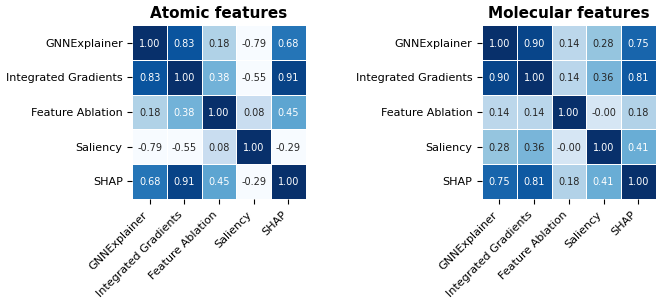

  saved figures/explainability_agreement.pdf
===== run_agreement finished in 0.0 min =====


,branch,method_a,method_b,spearman,top_k,top_k_overlap
0,Atomic,GNNExplainer,Integrated Gradients,0.832672,5,0.4
1,Atomic,GNNExplainer,Saliency,-0.789192,5,0.0
2,Atomic,GNNExplainer,SHAP,0.679286,5,0.4
3,Atomic,Integrated Gradients,Saliency,-0.552893,5,0.0
4,Atomic,Integrated Gradients,SHAP,0.913143,5,1.0
5,Atomic,Feature Ablation,GNNExplainer,0.180430,5,0.4
6,Atomic,Feature Ablation,Integrated Gradients,0.380095,5,0.4
7,Atomic,Feature Ablation,Saliency,0.084249,5,0.2
8,Atomic,Feature Ablation,SHAP,0.449939,5,0.4
9,Atomic,SHAP,Saliency,-0.294261,5,0.0


In [24]:
explain.run_agreement()

### Does removing the top-ranked descriptors matter more than removing random ones?

In [25]:
explain.run_deletion_check(setup)


===== run_deletion_check started 2026-11-14 11:41:48 =====
              method  k  mean_abs_change_top_k  mean_abs_change_random_k  random_sd
        GNNExplainer  5                 0.1111                    0.0711     0.0116
        GNNExplainer 10                 0.1218                    0.0731     0.0092
        GNNExplainer 20                 0.1509                    0.0795     0.0156
Integrated Gradients  5                 0.0871                    0.0703     0.0102
Integrated Gradients 10                 0.1090                    0.0750     0.0151
Integrated Gradients 20                 0.1380                    0.0844     0.0179
    Feature Ablation  5                 0.0676                    0.0690     0.0110
    Feature Ablation 10                 0.1003                    0.0720     0.0114
    Feature Ablation 20                 0.1528                    0.0815     0.0158
            Saliency  5                 0.0941                    0.0665     0.0094
            Sali

,method,k,mean_abs_change_top_k,mean_abs_change_random_k,random_sd
0,GNNExplainer,5,0.111112,0.071063,0.011560
1,GNNExplainer,10,0.121807,0.073118,0.009166
2,GNNExplainer,20,0.150880,0.079540,0.015567
3,Integrated Gradients,5,0.087091,0.070329,0.010203
4,Integrated Gradients,10,0.108976,0.074970,0.015122
5,Integrated Gradients,20,0.137956,0.084372,0.017875
6,Feature Ablation,5,0.067621,0.068982,0.011016
7,Feature Ablation,10,0.100342,0.071996,0.011410
8,Feature Ablation,20,0.152764,0.081454,0.015789
9,Saliency,5,0.094102,0.066526,0.009431


## 10. Look at the results


eda/dataset_summary


,subset,compounds,active,inactive,active_pct
0,Full dataset,123745,12685,111060,10.25
1,Development set,98995,9962,89033,10.06
2,Test set,24750,2723,22027,11.00



tuning/hyperparameter_table


,Model,Hidden size,Layers,Dropout,Learning rate,Weight decay,Pooling,CV AUROC
0,GCN,256,4,0.1,0.0001,0.00050,mean_max,0.943 ± 0.003
1,GAT,256,3,0.3,0.0005,0.00001,mean,0.943 ± 0.003
2,GCN-Transformer,256,4,0.1,0.0001,0.00050,mean_max,0.943 ± 0.003
3,GAT-Transformer,256,3,0.3,0.0005,0.00001,mean,0.943 ± 0.003



cross_validation/cv_mean_std_table


,model,accuracy,balanced_accuracy,auc,pr_auc,precision,recall,f1,mcc
0,gcn,0.867 ± 0.012,0.876 ± 0.004,0.943 ± 0.003,0.694 ± 0.020,0.425 ± 0.026,0.886 ± 0.008,0.574 ± 0.023,0.555 ± 0.020
1,gat,0.869 ± 0.016,0.875 ± 0.003,0.943 ± 0.003,0.702 ± 0.019,0.428 ± 0.041,0.882 ± 0.016,0.576 ± 0.033,0.556 ± 0.027
2,gcn_transformer,0.857 ± 0.028,0.874 ± 0.008,0.943 ± 0.003,0.695 ± 0.012,0.410 ± 0.050,0.895 ± 0.022,0.560 ± 0.045,0.544 ± 0.039
3,gat_transformer,0.875 ± 0.007,0.876 ± 0.005,0.943 ± 0.003,0.701 ± 0.019,0.440 ± 0.012,0.877 ± 0.015,0.586 ± 0.011,0.565 ± 0.009
4,baseline_gradient_boosting,0.864 ± 0.011,0.869 ± 0.005,0.935 ± 0.005,0.647 ± 0.023,0.417 ± 0.033,0.876 ± 0.005,0.565 ± 0.030,0.544 ± 0.025
5,baseline_random_forest,0.857 ± 0.014,0.867 ± 0.003,0.933 ± 0.005,0.645 ± 0.027,0.405 ± 0.033,0.878 ± 0.013,0.554 ± 0.029,0.534 ± 0.023
6,baseline_logistic_regression,0.865 ± 0.007,0.849 ± 0.003,0.920 ± 0.004,0.559 ± 0.023,0.415 ± 0.024,0.829 ± 0.003,0.553 ± 0.021,0.524 ± 0.017
7,baseline_linear_svm,0.865 ± 0.008,0.849 ± 0.005,0.920 ± 0.004,0.557 ± 0.024,0.416 ± 0.025,0.829 ± 0.003,0.553 ± 0.023,0.525 ± 0.019
8,baseline_knn,0.856 ± 0.015,0.846 ± 0.008,0.915 ± 0.007,0.562 ± 0.029,0.399 ± 0.032,0.833 ± 0.009,0.539 ± 0.029,0.511 ± 0.027


... (6 outputs left out)


explainability/explainability_agreement


,branch,method_a,method_b,spearman,top_k,top_k_overlap
0,Atomic,GNNExplainer,Integrated Gradients,0.832672,5,0.4
1,Atomic,GNNExplainer,Saliency,-0.789192,5,0.0
2,Atomic,GNNExplainer,SHAP,0.679286,5,0.4
3,Atomic,Integrated Gradients,Saliency,-0.552893,5,0.0
4,Atomic,Integrated Gradients,SHAP,0.913143,5,1.0
5,Atomic,Feature Ablation,GNNExplainer,0.180430,5,0.4
6,Atomic,Feature Ablation,Integrated Gradients,0.380095,5,0.4
7,Atomic,Feature Ablation,Saliency,0.084249,5,0.2
8,Atomic,Feature Ablation,SHAP,0.449939,5,0.4
9,Atomic,SHAP,Saliency,-0.294261,5,0.0



explainability/explainability_deletion_check


,method,k,mean_abs_change_top_k,mean_abs_change_random_k,random_sd
0,GNNExplainer,5,0.111112,0.071063,0.011560
1,GNNExplainer,10,0.121807,0.073118,0.009166
2,GNNExplainer,20,0.150880,0.079540,0.015567
3,Integrated Gradients,5,0.087091,0.070329,0.010203
4,Integrated Gradients,10,0.108976,0.074970,0.015122
5,Integrated Gradients,20,0.137956,0.084372,0.017875
6,Feature Ablation,5,0.067621,0.068982,0.011016
7,Feature Ablation,10,0.100342,0.071996,0.011410
8,Feature Ablation,20,0.152764,0.081454,0.015789
9,Saliency,5,0.094102,0.066526,0.009431


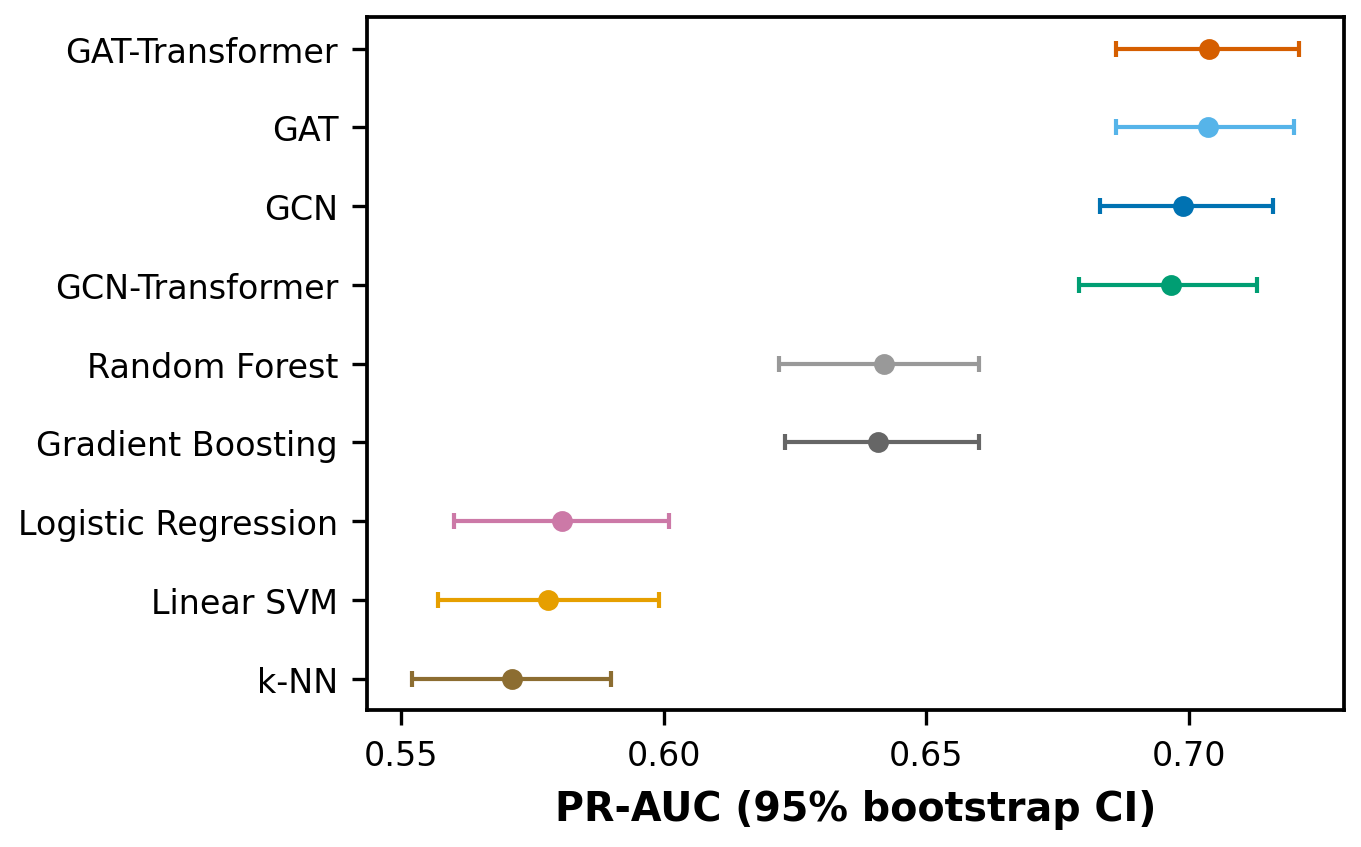

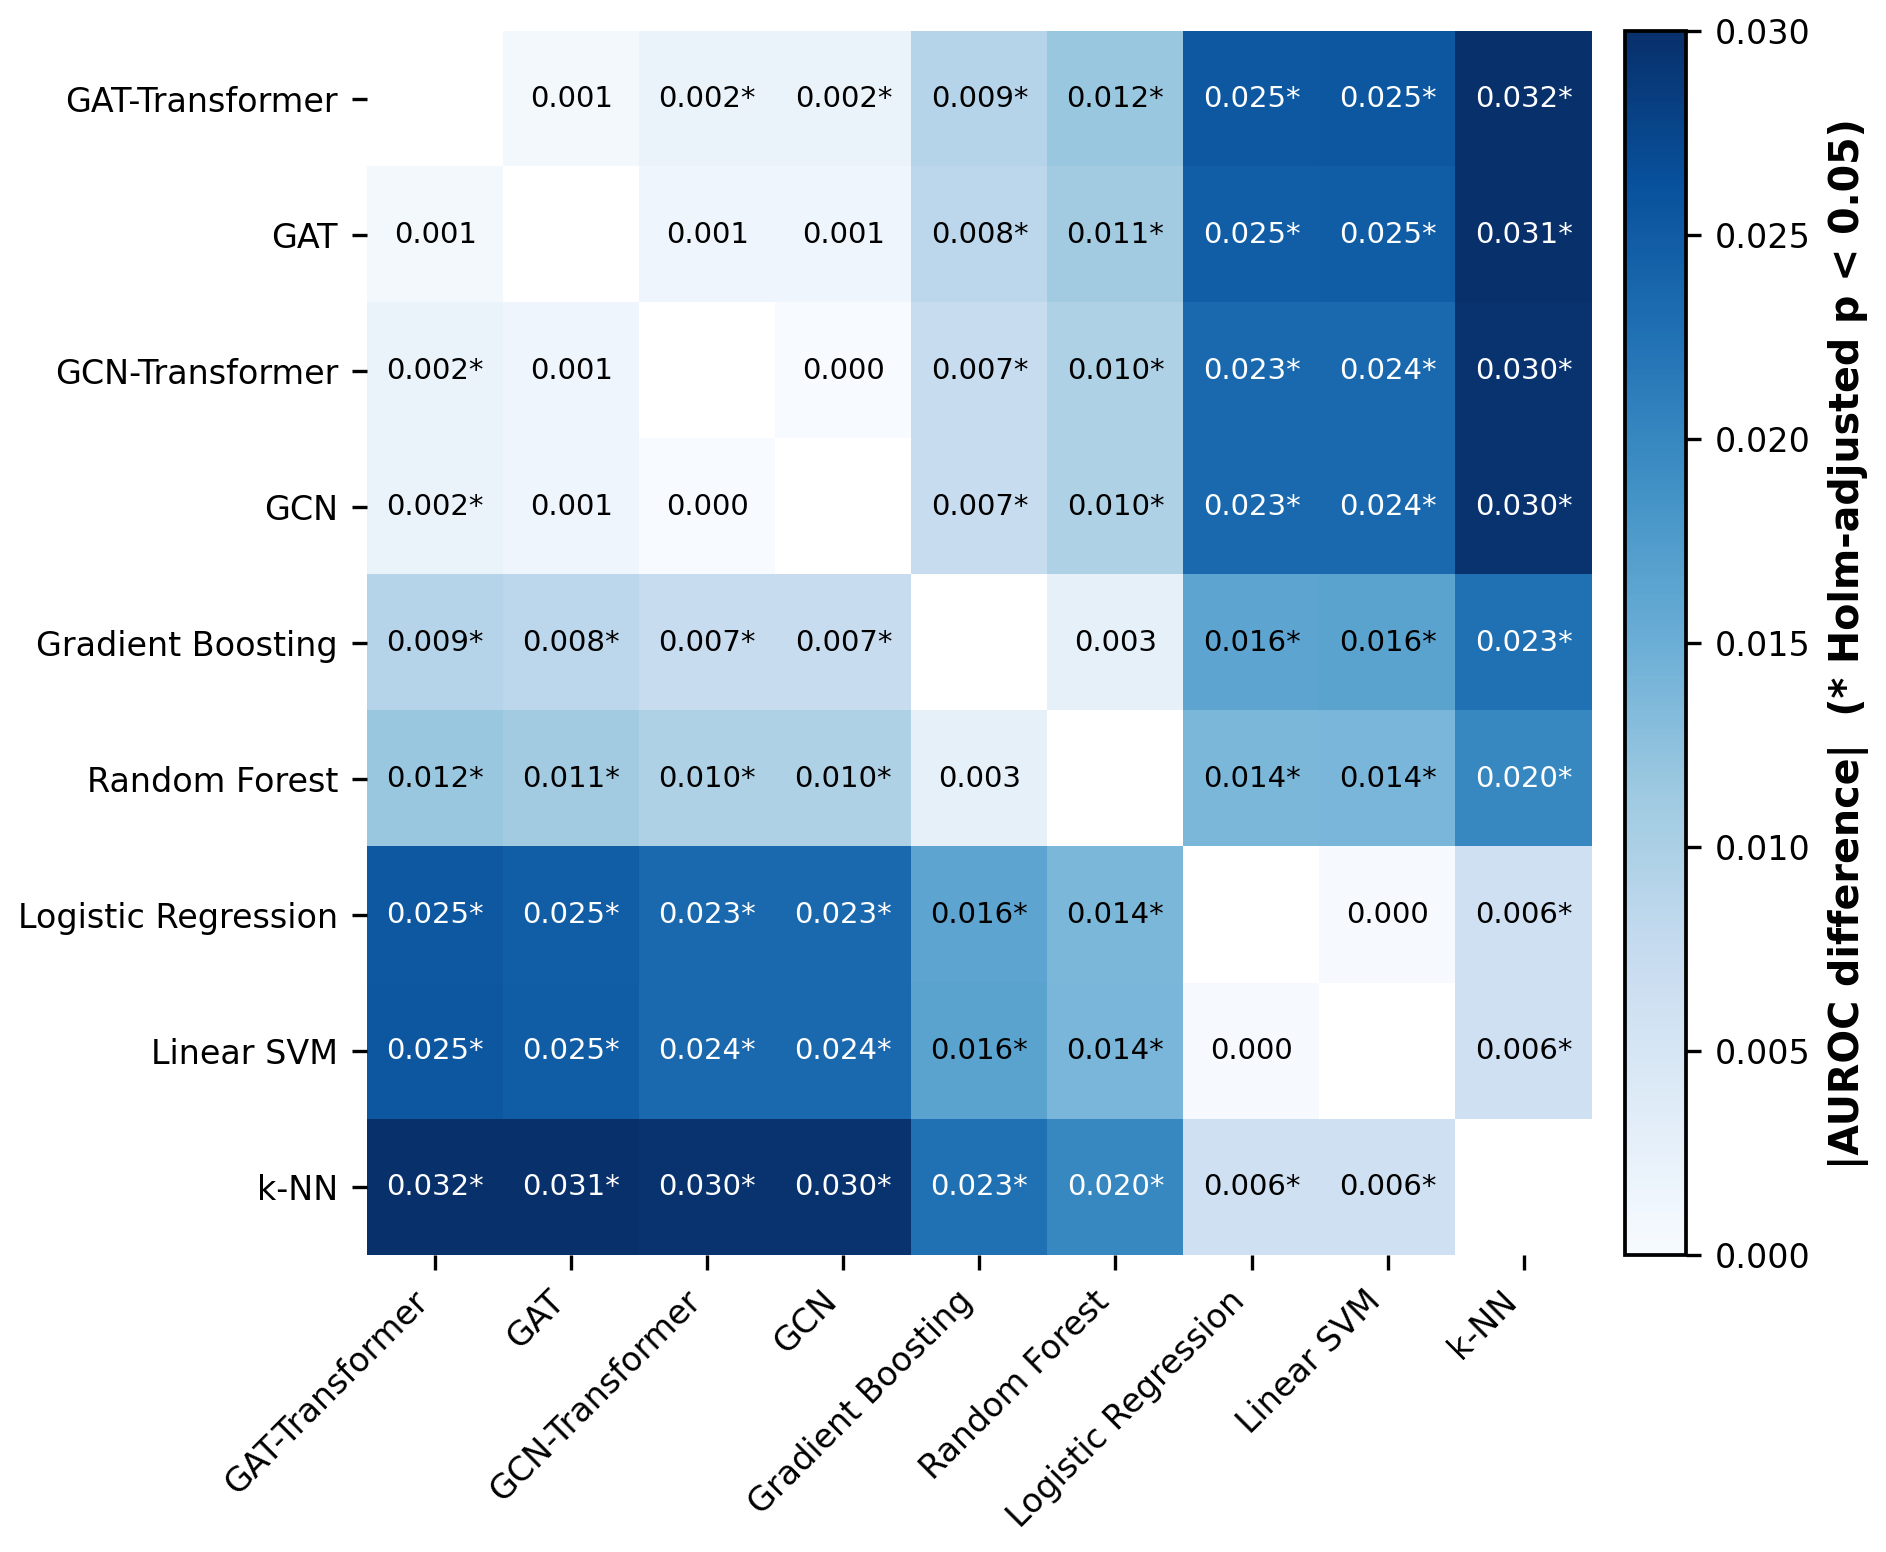

In [26]:
from IPython.display import Image, display
for folder, f in [("eda", "dataset_summary"), ("tuning", "hyperparameter_table"), ("cross_validation", "cv_mean_std_table"),
                  ("test_results", "test_set_metrics_table"), ("test_results", "bootstrap_ci_table"),
                  ("test_results", "seed_repeat_table"), ("explainability", "explainability_agreement"),
                  ("explainability", "explainability_deletion_check")]:
    p = os.path.join(OUT, folder, f + ".csv")
    if os.path.exists(p):
        print("\n" + folder + "/" + f); display(pd.read_csv(p))
for f in ["prauc_ci", "delong_heatmap"]:       # the other figures are PDF only (original style); open them from figures/
    p = os.path.join(OUT, "figures", f + ".png")
    if os.path.exists(p):
        display(Image(p, width=700))